In [1]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, StateGraph
from typing_extensions import TypedDict

In [2]:
class State(TypedDict):
  messages: list
  approved: bool  # Set by human review

In [3]:
def model_node(state: State):
  return {"messages": state["messages"] + ["Requesting tool execution..."]}

In [4]:
def tools_node(state: State):
  # Runs ONLY if approved
  return {"messages": state["messages"] + ["Tool executed successfully!"]}

In [5]:
# Router decides whether to go to tools or straight to END
py_router = "tools"  # or condition based on state

In [6]:
def route_action(state: State):
  if state.get("approved", False):
    return "run_tool"
  return "end_workflow"  # Bypasses tools entirely!

In [7]:
workflow = StateGraph(State)
workflow.add_node("model", model_node)
workflow.add_node("tools", tools_node)

workflow.set_entry_point("model")

# Conditional edge right out of the model
workflow.add_conditional_edges(
    "model", route_action, {"run_tool": "tools", "end_workflow": END}
)

workflow.add_edge("tools", END)

In [8]:
# Compile with checkpointer and interrupt before tools
checkpointer = MemorySaver()
app = workflow.compile(checkpointer=checkpointer, interrupt_before=["tools"])

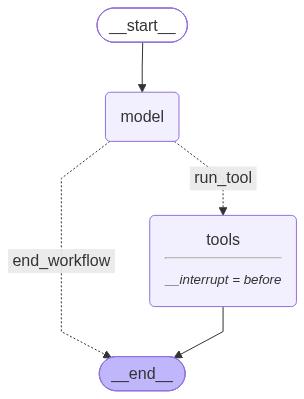

In [9]:
app

In [10]:
config = {"configurable": {"thread_id": "hitl_session_2"}}

for event in app.stream({"messages": ["Delete user database"], "action_approved": False},config = config ,stream_mode="updates"):
  print(event)
  print("-" * 40)

{'model': {'messages': ['Delete user database', 'Requesting tool execution...']}}
----------------------------------------


In [11]:
config = {"configurable": {"thread_id": "hitl_session_2"}}

for event in app.stream({"messages": ["Delete user database"], "action_approved": False},config = config ,stream_mode="values"):
  print(event)
  print("-" * 40)

{'messages': ['Delete user database']}
----------------------------------------
{'messages': ['Delete user database', 'Requesting tool execution...']}
----------------------------------------
